# EA Sports FC 26 — Modelos predictivos

**Introducción a la Ciencia de Datos — Equipo Videojuegos**

**Etapa 3 del proyecto.** Hasta acá hicimos dos cosas:

- **Notebook 01:** cargamos, limpiamos y ordenamos los datos.
- **Notebook 02:** medimos qué atributos *acompañan* al OVR (correlaciones).

Ahora damos el paso siguiente: **pasar de describir a predecir**. Un modelo no se
limita a decir "estas dos cosas se mueven juntas": intenta **calcular el OVR de un
jugador a partir de sus atributos**, y después se lo pone a prueba con jugadores que
nunca vio.

Si el modelo acierta, quiere decir que entendimos de verdad cómo se arma el OVR.

## 0. Preparación

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from pathlib import Path

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

DIR_BASE = Path.cwd()
for carpeta in [DIR_BASE, *DIR_BASE.parents]:
    if (carpeta / "data" / "processed").is_dir():
        DIR_BASE = carpeta
        break
else:
    raise FileNotFoundError("No encuentro data/processed. ¿Corriste antes el notebook 01?")

DIR_LIMPIO = DIR_BASE / "data" / "processed"
DIR_FIGURAS = DIR_BASE / "output" / "figuras"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

campo = pd.read_csv(DIR_LIMPIO / "jugadores_campo_limpio.csv", encoding="utf-8")
print(f"Jugadores de campo: {len(campo):,}".replace(",", "."))

Jugadores de campo: 15.859


### Estilo de los gráficos

El mismo del notebook 01 y 02, para que la presentación se vea coherente.

In [2]:
SUPERFICIE, TINTA = "#fcfcfb", "#0b0b0b"
TINTA_SUAVE, TINTA_TENUE, GRILLA = "#52514e", "#898781", "#e1e0d9"
AZUL, AZUL_CLARO, NARANJA, AQUA, GRIS = "#2a78d6", "#b7d3f6", "#eb6834", "#1baf7a", "#c3c2b7"

ESCALA_PESOS = LinearSegmentedColormap.from_list(
    "pesos", ["#a32a29", "#e34948", "#f0efec", "#86b6ef", "#184f95"]
)

mpl.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "savefig.facecolor": SUPERFICIE, "font.family": "sans-serif", "font.size": 11,
    "text.color": TINTA, "axes.labelcolor": TINTA_SUAVE, "axes.edgecolor": GRIS,
    "xtick.color": TINTA_TENUE, "ytick.color": TINTA_TENUE,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GRILLA, "grid.linewidth": 0.8,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})


def poner_titulo(ax, titulo, subtitulo, alto=(1.14, 1.045)):
    ax.text(0, alto[0], titulo, transform=ax.transAxes, fontsize=14,
            fontweight="bold", color=TINTA, va="bottom", ha="left")
    ax.text(0, alto[1], subtitulo, transform=ax.transAxes, fontsize=10.5,
            color=TINTA_SUAVE, va="bottom", ha="left")


def coma(valor, decimales=2):
    """0.896 -> '0,90' (separador decimal rioplatense)."""
    return f"{valor:.{decimales}f}".replace(".", ",")


def miles(entero):
    """3968 -> '3.968'. Sólo toca el número, no el texto que lo rodea."""
    return f"{int(entero):,}".replace(",", ".")


def porcentaje(fraccion, decimales=1):
    """0.9962 -> '99,6 %'."""
    return f"{fraccion * 100:.{decimales}f}".replace(".", ",") + " %"


def guardar(fig, nombre):
    fig.savefig(DIR_FIGURAS / nombre)
    print(f"✓ {nombre}")

---
# PARTE 1 — ¿Qué es un modelo y cómo se sabe si es bueno?

Un **modelo** es una fórmula que aprende sola a partir de los datos. Nosotros le damos
los atributos de miles de jugadores y su OVR, y el modelo busca la combinación que mejor
reproduce ese OVR.

**El problema:** un modelo podría hacer trampa memorizando los jugadores en vez de
aprender la regla. Si lo evaluamos con los mismos jugadores con los que aprendió, no nos
enteramos.

**La solución — separar en dos grupos:**

| Grupo | Para qué | Cuántos |
|---|---|---|
| **Entrenamiento (75%)** | El modelo aprende acá | ~11.900 jugadores |
| **Prueba (25%)** | Lo evaluamos con jugadores que nunca vio | ~3.965 jugadores |

Es como estudiar con los ejercicios del práctico y rendir con un examen distinto.

**Las dos notas que le ponemos:**

- **R²** — qué porcentaje de la variación del OVR logra explicar. Va de 0 a 1: un 0,90
  significa que explica el 90%.
- **Error medio** — de cuántos puntos de OVR se equivoca en promedio. Si da 2, el modelo
  dice 84 cuando en realidad es 86.

## 1.1 Los grupos de atributos que vamos a probar

In [3]:
CARAS = ["pac", "sho", "pas", "dri", "def", "phy"]

ATRIBUTOS = [
    "acceleration", "sprint_speed", "positioning", "finishing", "shot_power",
    "long_shots", "volleys", "penalties", "vision", "crossing", "free_kick_accuracy",
    "short_passing", "long_passing", "curve", "dribbling", "agility", "balance",
    "reactions", "ball_control", "composure", "interceptions", "heading_accuracy",
    "def_awareness", "standing_tackle", "sliding_tackle", "jumping", "stamina",
    "strength", "aggression",
]

NOMBRES = {
    "pac": "PAC (ritmo)", "sho": "SHO (tiro)", "pas": "PAS (pase)", "dri": "DRI (regate)",
    "def": "DEF (defensa)", "phy": "PHY (físico)",
    "reactions": "Reacciones", "composure": "Serenidad", "short_passing": "Pase corto",
    "ball_control": "Control del balón", "long_passing": "Pase largo",
    "dribbling": "Regate (detalle)", "vision": "Visión de juego",
    "shot_power": "Potencia de tiro", "crossing": "Centros", "jumping": "Salto",
    "curve": "Comba", "agility": "Agilidad", "finishing": "Definición",
    "positioning": "Posicionamiento", "long_shots": "Tiros lejanos", "volleys": "Voleas",
    "penalties": "Penales", "free_kick_accuracy": "Tiros libres",
    "acceleration": "Aceleración", "sprint_speed": "Velocidad punta",
    "balance": "Equilibrio", "interceptions": "Intercepciones",
    "heading_accuracy": "Cabeceo", "def_awareness": "Corte defensivo",
    "standing_tackle": "Entrada", "sliding_tackle": "Barrida", "stamina": "Resistencia",
    "strength": "Fuerza", "aggression": "Agresividad",
}

SEMILLA = 42  # fija el azar, para que el resultado sea siempre el mismo


def evaluar(nombre, X, y, modelo=None):
    """Entrena con el 75% y evalúa con el 25% restante. Devuelve el modelo y las métricas."""
    X_entren, X_prueba, y_entren, y_prueba = train_test_split(
        X, y, test_size=0.25, random_state=SEMILLA
    )
    m = LinearRegression() if modelo is None else modelo
    m.fit(X_entren, y_entren)
    predicho = m.predict(X_prueba)
    r2 = r2_score(y_prueba, predicho)
    error = mean_absolute_error(y_prueba, predicho)
    print(f"{nombre:46s}  R² = {r2:.4f}   error medio = {error:.2f} puntos")
    return {"nombre": nombre, "modelo": m, "r2": r2, "error": error,
            "y_prueba": y_prueba, "predicho": predicho}

---
# PARTE 2 — Cuatro modelos, cada uno mejor que el anterior

## Modelo 1 — Sólo con las 6 caras de la carta

Empezamos por lo más simple: ¿alcanza con los seis números que el jugador ve en la carta
para reconstruir el OVR?

In [4]:
y = campo["ovr"]
m1 = evaluar("1. Sólo las 6 caras de la carta", campo[CARAS], y)

1. Sólo las 6 caras de la carta                 R² = 0.7725   error medio = 2.66 puntos


Explica el 77% y se equivoca en 2,7 puntos de media. No está mal, pero para un dato que
el juego calcula con una fórmula exacta, 2,7 puntos es mucho: es la diferencia entre una
carta de 84 y una de 87.

## Modelo 2 — Con los 29 atributos de detalle

In [5]:
m2 = evaluar("2. Los 29 atributos de detalle", campo[ATRIBUTOS], y)
m3 = evaluar("3. Las caras + los 29 atributos", campo[CARAS + ATRIBUTOS], y)

2. Los 29 atributos de detalle                  R² = 0.9135   error medio = 1.61 puntos
3. Las caras + los 29 atributos                 R² = 0.9134   error medio = 1.61 puntos


Dos cosas para destacar:

1. **Pasar de las caras a los atributos mejora muchísimo** (de 0,77 a 0,91). Confirma lo
   que veníamos diciendo: lo que define el OVR está en los atributos de detalle.
2. **Agregar las caras al modelo 2 no mejora nada** (0,9135 → 0,9134). Las seis caras no
   aportan información nueva: son un **resumen** de los atributos de detalle. Por eso el
   modelo ya las tenía, sin saberlo.

## Modelo 3 — Random Forest

Hasta acá usamos una **regresión lineal**: una suma ponderada, donde cada atributo aporta
siempre lo mismo. Un **Random Forest** es distinto: combina cientos de árboles de
decisión y puede captar reglas del tipo *"si es defensor, mirá la entrada; si es
delantero, mirá la definición"*.

In [6]:
m4 = evaluar("4. Random Forest (29 atributos)", campo[ATRIBUTOS], y,
             RandomForestRegressor(n_estimators=120, random_state=SEMILLA, n_jobs=-1))

4. Random Forest (29 atributos)                 R² = 0.9727   error medio = 0.87 puntos


Salta a 0,97 y baja el error a menos de un punto. Que un modelo capaz de cambiar de regla
según el jugador funcione tanto mejor es **una pista fuerte**: sugiere que el OVR no se
calcula igual para todos.

## Modelo 4 — Un modelo por cada posición

Si la pista es cierta, entonces en vez de un modelo para todos conviene **uno por
posición**. Es exactamente lo que vimos en el notebook 02: a un central lo evalúan por
cómo defiende y a un delantero por cómo define.

In [7]:
resultados_pos = []
modelos_pos = {}

for posicion in sorted(campo["position"].unique()):
    sub = campo[campo["position"] == posicion]
    X_entren, X_prueba, y_entren, y_prueba = train_test_split(
        sub[ATRIBUTOS], sub["ovr"], test_size=0.25, random_state=SEMILLA
    )
    modelo = LinearRegression().fit(X_entren, y_entren)
    predicho = modelo.predict(X_prueba)
    modelos_pos[posicion] = modelo
    resultados_pos.append({
        "posición": posicion, "jugadores": len(sub),
        "R²": r2_score(y_prueba, predicho),
        "error": mean_absolute_error(y_prueba, predicho),
        "y_prueba": y_prueba, "predicho": predicho,
    })

tabla_pos = pd.DataFrame(resultados_pos)[["posición", "jugadores", "R²", "error"]]
print(tabla_pos.round(4).to_string(index=False))

# Juntamos las predicciones de las 11 posiciones y medimos sobre el total, para que
# el número que mostramos sea el mismo que el del gráfico.
y_real = np.concatenate([r["y_prueba"].values for r in resultados_pos])
y_pred = np.concatenate([r["predicho"] for r in resultados_pos])
errores = y_pred - y_real

r2_pos = r2_score(y_real, y_pred)
error_pos = mean_absolute_error(y_real, y_pred)
error_maximo = np.abs(errores).max()
dentro_de_uno = (np.abs(errores) <= 1).mean()

print(f"\nLos 11 modelos juntos, sobre {miles(len(y_real))} jugadores de prueba:")
print(f"  R² = {r2_pos:.4f}   error medio = {error_pos:.2f} puntos   error máximo = {error_maximo:.2f}")
print(f"  El {porcentaje(dentro_de_uno)} de los jugadores queda a menos de 1 punto de su OVR real.")

posición  jugadores     R²  error
     CAM       1034 0.9976 0.3020
      CB       3252 0.9975 0.2835
     CDM       1376 0.9975 0.2847
      CM       2219 0.9981 0.2767
      LB       1335 0.9974 0.2889
      LM       1058 0.9970 0.2962
      LW        364 0.9981 0.3201
      RB       1394 0.9973 0.2967
      RM        978 0.9976 0.2959
      RW        373 0.9979 0.3277
      ST       2476 0.9978 0.2743

Los 11 modelos juntos, sobre 3.968 jugadores de prueba:
  R² = 0.9977   error medio = 0.29 puntos   error máximo = 1.44
  El 99,6 % de los jugadores queda a menos de 1 punto de su OVR real.


**Este es el resultado del trabajo.** Con un modelo por posición el R² sube a **0,998** y
el error baja a **0,29 puntos de OVR**. El peor caso de los 3.968 jugadores de prueba se
equivoca por 1,4 puntos, y el 99,6% queda a menos de 1 punto.

En la práctica: le damos los atributos de un jugador que el modelo nunca vio y le acierta
el OVR casi exacto.

## Gráfico 12 — Los cuatro modelos comparados

✓ 12_comparacion_modelos.png


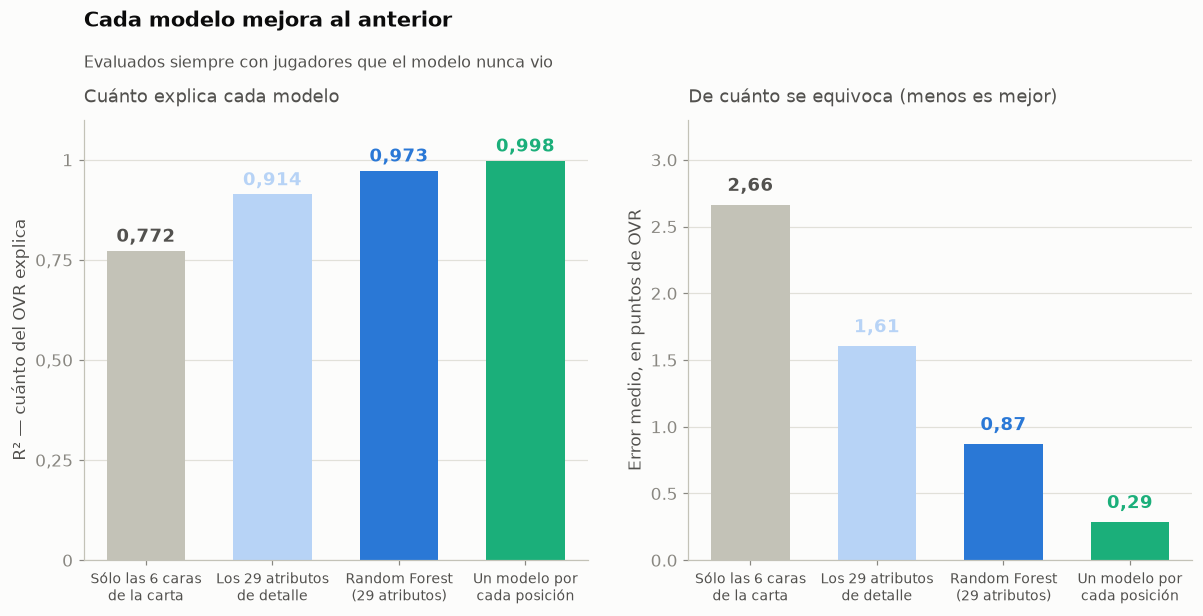

In [8]:
comparacion = [
    ("Sólo las 6 caras\nde la carta", m1["r2"], m1["error"], GRIS),
    ("Los 29 atributos\nde detalle", m2["r2"], m2["error"], AZUL_CLARO),
    ("Random Forest\n(29 atributos)", m4["r2"], m4["error"], AZUL),
    ("Un modelo por\ncada posición", r2_pos, error_pos, AQUA),
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

ax = axes[0]
ax.bar(range(4), [c[1] for c in comparacion], color=[c[3] for c in comparacion], width=0.62)
for i, c in enumerate(comparacion):
    ax.text(i, c[1] + 0.012, coma(c[1], 3), ha="center", va="bottom",
            fontsize=12, fontweight="bold", color=c[3] if i > 0 else TINTA_SUAVE)
ax.set_xticks(range(4), [c[0] for c in comparacion], fontsize=9, color=TINTA_SUAVE)
ax.set_ylim(0, 1.1)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0], ["0", "0,25", "0,50", "0,75", "1"])
ax.set_ylabel("R² — cuánto del OVR explica")
ax.yaxis.grid(True, zorder=0)
ax.set_axisbelow(True)
ax.text(0, 1.03, "Cuánto explica cada modelo", transform=ax.transAxes,
        fontsize=11.5, color=TINTA_SUAVE, va="bottom", ha="left")

ax = axes[1]
ax.bar(range(4), [c[2] for c in comparacion], color=[c[3] for c in comparacion], width=0.62)
for i, c in enumerate(comparacion):
    ax.text(i, c[2] + 0.07, coma(c[2]), ha="center", va="bottom",
            fontsize=12, fontweight="bold", color=c[3] if i > 0 else TINTA_SUAVE)
ax.set_xticks(range(4), [c[0] for c in comparacion], fontsize=9, color=TINTA_SUAVE)
ax.set_ylim(0, 3.3)
ax.set_ylabel("Error medio, en puntos de OVR")
ax.yaxis.grid(True, zorder=0)
ax.set_axisbelow(True)
ax.text(0, 1.03, "De cuánto se equivoca (menos es mejor)", transform=ax.transAxes,
        fontsize=11.5, color=TINTA_SUAVE, va="bottom", ha="left")

poner_titulo(axes[0], "Cada modelo mejora al anterior",
             "Evaluados siempre con jugadores que el modelo nunca vio",
             alto=(1.20, 1.11))

guardar(fig, "12_comparacion_modelos.png")
plt.show()

## Gráfico 13 — Qué tan bien acierta el mejor modelo

Un R² alto es un número. Para verlo de verdad, dibujamos **lo que el modelo predijo
contra lo que el jugador realmente valía**. Si el modelo fuera perfecto, todos los puntos
caerían sobre la diagonal.

✓ 13_predicho_vs_real.png


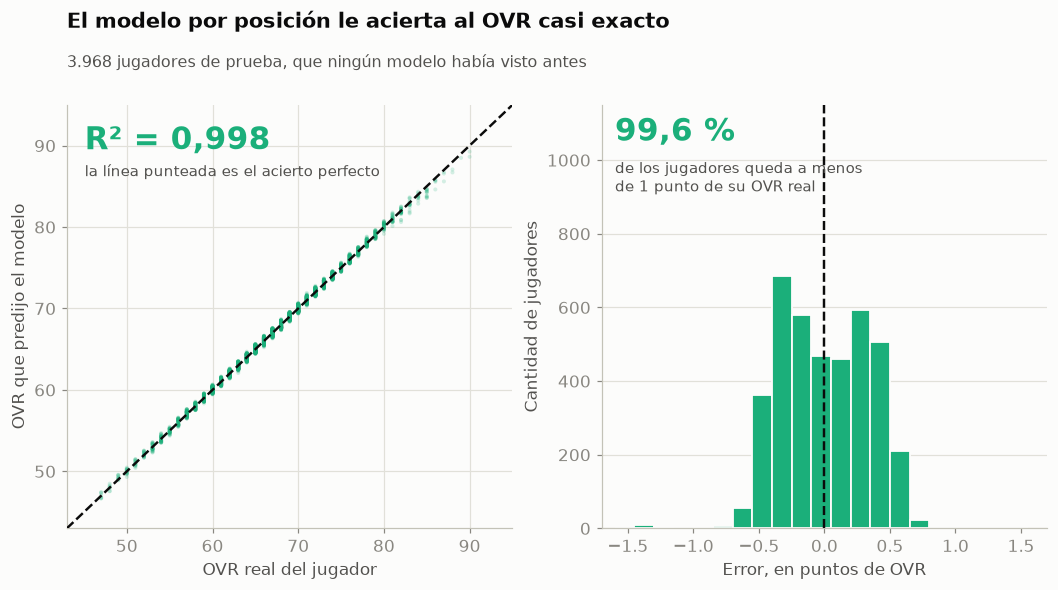

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))

ax = axes[0]
ax.scatter(y_real, y_pred, s=7, alpha=0.18, color=AQUA, edgecolors="none", zorder=2)
lim = [43, 95]
ax.plot(lim, lim, color=TINTA, linewidth=1.6, linestyle="--", zorder=3)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("OVR real del jugador")
ax.set_ylabel("OVR que predijo el modelo")
ax.grid(True, zorder=0)
ax.set_axisbelow(True)
ax.text(0.04, 0.95, f"R² = {coma(r2_pos, 3)}", transform=ax.transAxes,
        fontsize=20, fontweight="bold", color=AQUA, va="top", ha="left")
ax.text(0.04, 0.86, "la línea punteada es el acierto perfecto",
        transform=ax.transAxes, fontsize=10, color=TINTA_SUAVE, va="top", ha="left")

ax = axes[1]
ax.hist(errores, bins=np.arange(-1.6, 1.65, 0.15), color=AQUA,
        edgecolor=SUPERFICIE, linewidth=1.2, zorder=2)
ax.axvline(0, color=TINTA, linewidth=1.6, linestyle="--", zorder=3)
ax.set_xlabel("Error, en puntos de OVR")
ax.set_ylabel("Cantidad de jugadores")
ax.set_xlim(-1.7, 1.7)
ax.set_ylim(0, 1150)          # aire arriba para que el texto no toque las barras
ax.grid(True, axis="y", zorder=0)
ax.set_axisbelow(True)
ax.text(0.03, 0.97, porcentaje(dentro_de_uno), transform=ax.transAxes,
        fontsize=20, fontweight="bold", color=AQUA, va="top", ha="left")
ax.text(0.03, 0.87, "de los jugadores queda a menos\nde 1 punto de su OVR real",
        transform=ax.transAxes, fontsize=10, color=TINTA_SUAVE, va="top", ha="left")

poner_titulo(axes[0], "El modelo por posición le acierta al OVR casi exacto",
             f"{miles(len(y_real))} jugadores de prueba, que ningún modelo había visto antes",
             alto=(1.17, 1.08))

guardar(fig, "13_predicho_vs_real.png")
plt.show()

## Gráfico 14 — Qué mira el Random Forest

El Random Forest puede decirnos **cuánto usó cada atributo** para decidir. Es otra forma
de responder la pregunta del proyecto, independiente de la correlación del notebook 02.

✓ 14_importancia_random_forest.png


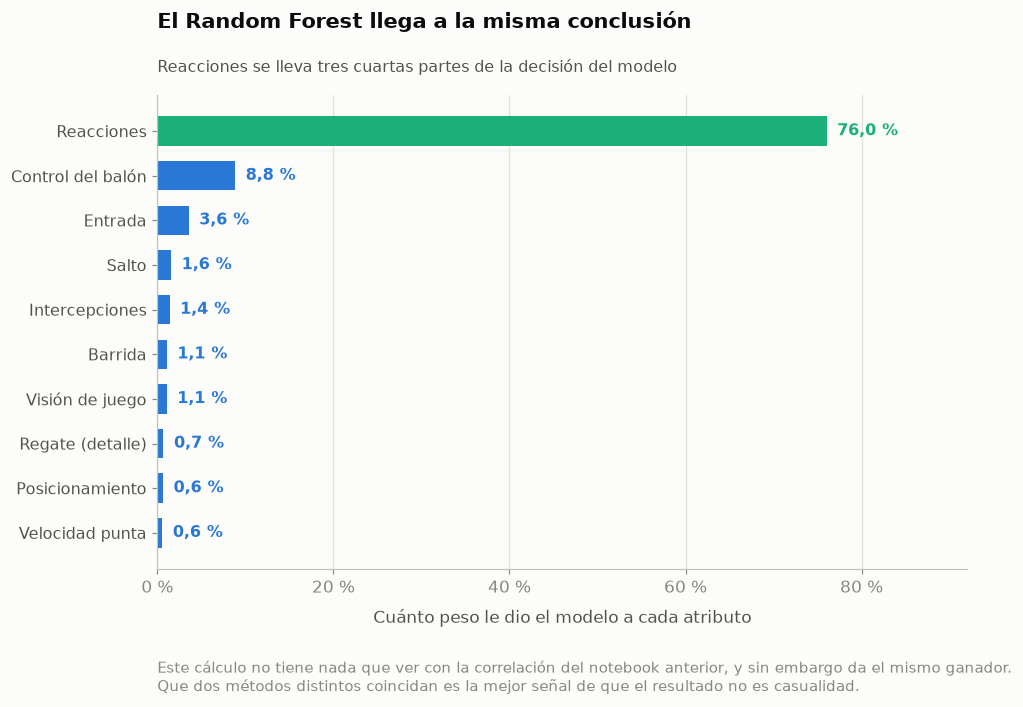

In [10]:
importancias = pd.Series(
    m4["modelo"].feature_importances_, index=ATRIBUTOS
).sort_values(ascending=False).head(10) * 100

fig, ax = plt.subplots(figsize=(9.5, 5.6))
posiciones = list(range(len(importancias)))[::-1]
colores = [AQUA if i == 0 else AZUL for i in range(len(importancias))]
ax.barh(posiciones, importancias.values, color=colores, height=0.66)

for y_, (nombre, valor) in zip(posiciones, importancias.items()):
    ax.text(valor + 1.2, y_, f"{coma(valor, 1)} %", ha="left", va="center",
            fontsize=10.5, fontweight="bold", color=AQUA if valor > 50 else AZUL)

ax.set_yticks(posiciones, [NOMBRES.get(a, a) for a in importancias.index],
              fontsize=10.5, color=TINTA_SUAVE)
ax.set_xlim(0, 92)
ax.set_xticks([0, 20, 40, 60, 80], ["0 %", "20 %", "40 %", "60 %", "80 %"])
ax.set_xlabel("Cuánto peso le dio el modelo a cada atributo", labelpad=8)
ax.xaxis.grid(True, zorder=0)
ax.set_axisbelow(True)

poner_titulo(ax, "El Random Forest llega a la misma conclusión",
             "Reacciones se lleva tres cuartas partes de la decisión del modelo",
             alto=(1.13, 1.04))
ax.text(0, -0.19,
        "Este cálculo no tiene nada que ver con la correlación del notebook anterior, y sin embargo "
        "da el mismo ganador.\nQue dos métodos distintos coincidan es la mejor señal de que el "
        "resultado no es casualidad.",
        transform=ax.transAxes, fontsize=9.5, color=TINTA_TENUE, va="top", ha="left")

guardar(fig, "14_importancia_random_forest.png")
plt.show()

---
# PARTE 3 — Lo que el modelo nos dejó ver

Acá viene lo más interesante. Cuando una regresión lineal aprende, lo que calcula es
**cuánto pesa cada atributo** en el resultado. Y como entrenamos un modelo por posición,
tenemos los pesos de cada posición por separado.

Dicho de otra forma: **el modelo reconstruyó la receta con la que EA arma el OVR.**

In [11]:
pesos = pd.DataFrame(
    {pos: pd.Series(modelo.coef_, index=ATRIBUTOS) for pos, modelo in modelos_pos.items()}
)

print("¿La suma de los pesos da 1? (si da ~1, el OVR es un promedio ponderado)\n")
resumen_suma = pd.DataFrame({
    "suma de pesos": pesos.sum().round(3),
    "punto de partida": [modelos_pos[p].intercept_ for p in pesos.columns],
}).round(2)
print(resumen_suma.to_string())

¿La suma de los pesos da 1? (si da ~1, el OVR es un promedio ponderado)

     suma de pesos  punto de partida
CAM           1.01             -0.69
CB            1.00             -0.02
CDM           1.01              0.17
CM            1.01             -0.66
LB            1.00              1.81
LM            1.01              0.50
LW            1.00             -0.10
RB            1.01              1.60
RM            1.00              1.18
RW            1.02             -0.90
ST            1.01             -0.48


**Los pesos suman 1 en las once posiciones** (entre 1,00 y 1,02), y el punto de partida
es chico: va de -0,9 a +1,8 sobre un OVR que ronda los 67 puntos.

Eso significa que el OVR es, en esencia, un **promedio ponderado de los atributos**: cada
posición usa su propia receta, pero los pesos siempre suman 1. No lo supimos de antemano:
lo dedujimos de los datos.

## Gráfico 15 — La receta de cada posición

✓ 15_pesos_por_posicion.png


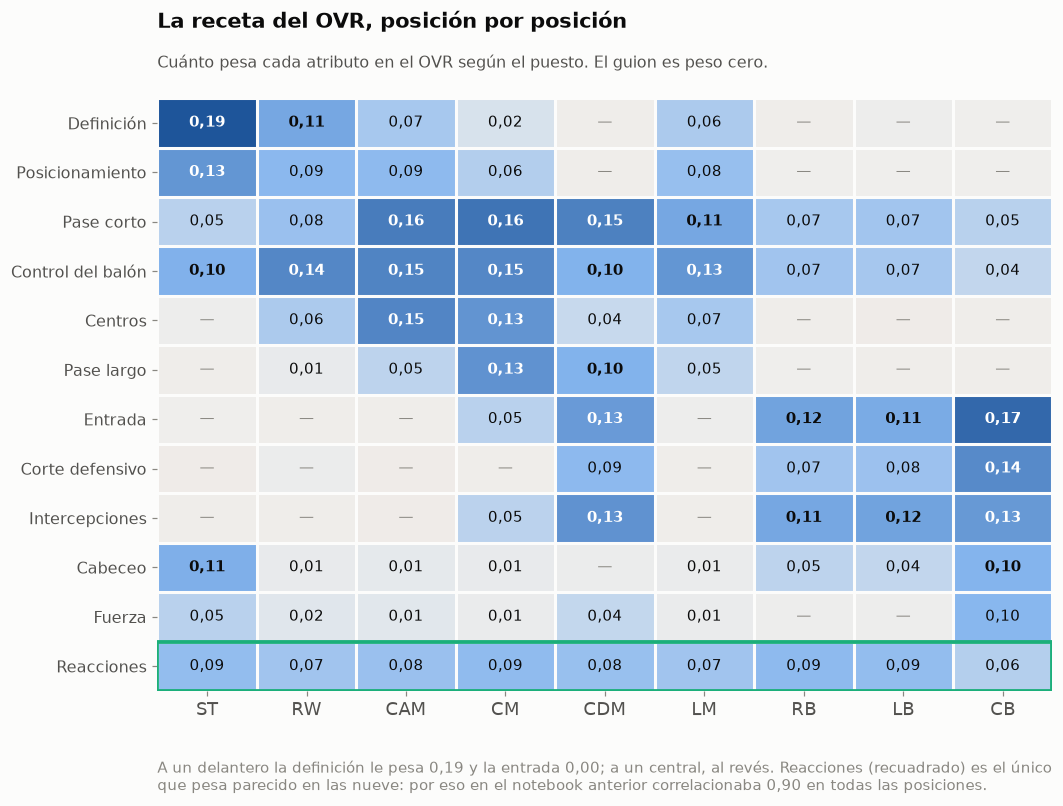

In [12]:
POSICIONES = ["ST", "RW", "CAM", "CM", "CDM", "LM", "RB", "LB", "CB"]
DESTACADOS = ["finishing", "positioning", "short_passing", "ball_control", "crossing",
              "long_passing", "standing_tackle", "def_awareness", "interceptions",
              "heading_accuracy", "strength", "reactions"]

matriz = pesos.loc[DESTACADOS, POSICIONES]

fig, ax = plt.subplots(figsize=(10.5, 7))
im = ax.imshow(matriz.values, cmap=ESCALA_PESOS,
               norm=TwoSlopeNorm(vmin=-0.2, vcenter=0, vmax=0.2), aspect="auto")

for i in range(len(DESTACADOS)):
    for j in range(len(POSICIONES)):
        valor = matriz.values[i, j]
        color = "white" if abs(valor) > 0.125 else TINTA
        peso = "bold" if valor > 0.1 else "normal"
        texto = coma(valor, 2) if abs(valor) >= 0.005 else "—"
        ax.text(j, i, texto, ha="center", va="center",
                fontsize=9.5, color=color if texto != "—" else TINTA_TENUE, fontweight=peso)

ax.set_xticks(range(len(POSICIONES)), POSICIONES, fontsize=11.5, color=TINTA_SUAVE)
ax.set_yticks(range(len(DESTACADOS)), [NOMBRES[a] for a in DESTACADOS],
              fontsize=10.5, color=TINTA_SUAVE)
ax.set_xticks(np.arange(len(POSICIONES) + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(len(DESTACADOS) + 1) - 0.5, minor=True)
ax.grid(which="minor", color=SUPERFICIE, linewidth=2)
ax.tick_params(which="minor", length=0)
for lado in ax.spines.values():
    lado.set_visible(False)

fila_reacciones = DESTACADOS.index("reactions")
from matplotlib.patches import Rectangle
ax.add_patch(Rectangle((-0.5, fila_reacciones - 0.5), len(POSICIONES), 1, fill=False,
                       edgecolor=AQUA, linewidth=2.5, zorder=5))

poner_titulo(ax, "La receta del OVR, posición por posición",
             "Cuánto pesa cada atributo en el OVR según el puesto. El guion es peso cero.",
             alto=(1.11, 1.045))
ax.text(0, -0.115,
        "A un delantero la definición le pesa 0,19 y la entrada 0,00; a un central, al revés. "
        "Reacciones (recuadrado) es el único\nque pesa parecido en las nueve: por eso en el "
        "notebook anterior correlacionaba 0,90 en todas las posiciones.",
        transform=ax.transAxes, fontsize=9.5, color=TINTA_TENUE, va="top", ha="left")

guardar(fig, "15_pesos_por_posicion.png")
plt.show()

---
# PARTE 4 — Conclusiones

In [13]:
conclusiones = pd.DataFrame([
    {"Resultado": "El OVR es un promedio ponderado",
     "Detalle": "Los pesos suman 1 en las 11 posiciones: lo dedujimos del modelo, no lo sabíamos."},
    {"Resultado": "Cada posición tiene su propia receta",
     "Detalle": "Definición pesa 0,19 en un delantero y 0,00 en un central."},
    {"Resultado": "Reacciones es el denominador común",
     "Detalle": "Pesa entre 0,05 y 0,09 en todas las posiciones. Es el único que nunca vale cero."},
    {"Resultado": "Las 6 caras son un resumen, no la fuente",
     "Detalle": "Agregarlas al modelo de atributos no mejora nada: la información ya estaba."},
    {"Resultado": "El mejor modelo se equivoca por 0,29 puntos",
     "Detalle": f"R² = {coma(r2_pos, 3)} sobre jugadores que nunca vio. El {porcentaje(dentro_de_uno)} queda a menos de 1 punto."},
    {"Resultado": "Dos métodos distintos coinciden",
     "Detalle": "Correlación y Random Forest, sin relación entre sí, dan el mismo ganador."},
])
print(conclusiones.to_string(index=False))

                                  Resultado                                                                          Detalle
            El OVR es un promedio ponderado Los pesos suman 1 en las 11 posiciones: lo dedujimos del modelo, no lo sabíamos.
       Cada posición tiene su propia receta                       Definición pesa 0,19 en un delantero y 0,00 en un central.
         Reacciones es el denominador común Pesa entre 0,05 y 0,09 en todas las posiciones. Es el único que nunca vale cero.
   Las 6 caras son un resumen, no la fuente      Agregarlas al modelo de atributos no mejora nada: la información ya estaba.
El mejor modelo se equivoca por 0,29 puntos    R² = 0,998 sobre jugadores que nunca vio. El 99,6 % queda a menos de 1 punto.
            Dos métodos distintos coinciden        Correlación y Random Forest, sin relación entre sí, dan el mismo ganador.


## De la correlación al modelo: qué ganamos

En el notebook 02 sabíamos que Reacciones **acompañaba** al OVR. No sabíamos por qué, ni
cuánto aportaba, ni si era causa o casualidad.

Ahora sabemos **cómo se calcula**: el OVR es un promedio ponderado de los atributos, con
pesos distintos por posición, y Reacciones es el único atributo con peso en todas. Eso
explica el misterio del notebook anterior.

---
# PARTE 5 — Poner la receta a prueba

Ya sabemos que el OVR es un promedio ponderado de los atributos de detalle, con una
receta por posición. Ahora nos hacemos tres preguntas más:

1. ¿Podemos calcular a mano el OVR de un jugador concreto?
2. ¿Hacen falta los 29 atributos, o con menos alcanza?
3. ¿Dónde se equivoca el modelo?

## Gráfico 18 — Calculemos el OVR de un jugador, paso a paso

Tomamos la receta de los delanteros y la aplicamos a un jugador conocido. Multiplicamos
cada atributo suyo por el peso que le corresponde y sumamos todo.

Kylian Mbappé  —  ST  —  OVR real: 91

  Definición            92 × 0,193  = 17,76
  Posicionamiento       91 × 0,131  = 11,94
  Control del balón     93 × 0,104  = 9,68
  Potencia de tiro      91 × 0,093  = 8,48
  Cabeceo               78 × 0,106  = 8,24
  Reacciones            91 × 0,087  = 7,95
  Regate (detalle)      92 × 0,065  = 6,02
  Velocidad punta       97 × 0,048  = 4,68
  Pase corto            87 × 0,050  = 4,35
  Los otros 20 atributos            = 11,30
  Punto de partida                = -0,48

  TOTAL PREDICHO = 89,93     OVR REAL = 91
✓ 18_ejemplo_calculo_ovr.png


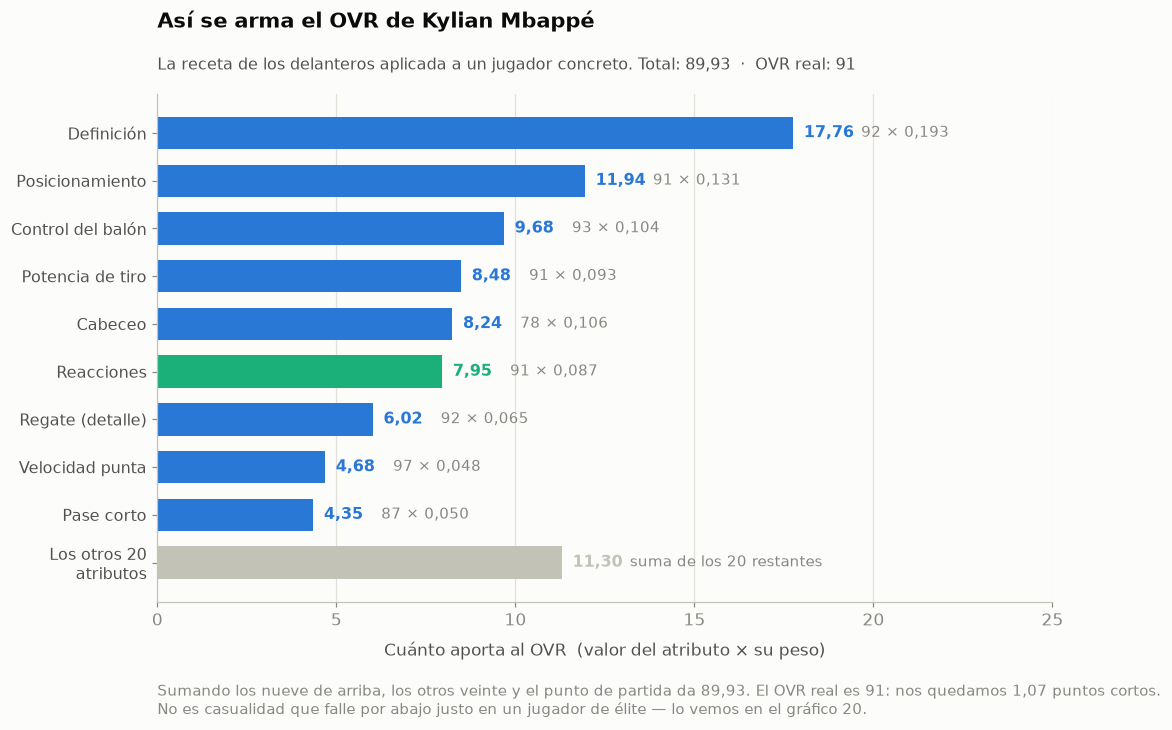

In [14]:
EJEMPLO_POSICION = "ST"
EJEMPLO_NOMBRE = "Mbapp"  # lo buscamos así para no depender del acento

delanteros = campo[campo["position"] == EJEMPLO_POSICION]
modelo_ej = modelos_pos[EJEMPLO_POSICION]
pesos_ej = pd.Series(modelo_ej.coef_, index=ATRIBUTOS)

jugador = delanteros[delanteros["name"].str.contains(EJEMPLO_NOMBRE, na=False)].iloc[0]
ovr_predicho = modelo_ej.predict(pd.DataFrame([jugador[ATRIBUTOS]]))[0]

# Cuánto aporta cada atributo = su valor x su peso
aportes = (pesos_ej * jugador[ATRIBUTOS]).sort_values(ascending=False)
principales = aportes.head(9)
resto = aportes.iloc[9:].sum()

print(f"{jugador['name']}  —  {EJEMPLO_POSICION}  —  OVR real: {jugador['ovr']}\n")
for atributo, aporte in principales.items():
    print(f"  {NOMBRES.get(atributo, atributo):20s} {int(jugador[atributo]):3d} × {coma(pesos_ej[atributo], 3)}"
          f"  = {coma(aporte)}")
print(f"  {'Los otros 20 atributos':20s}            = {coma(resto)}")
print(f"  {'Punto de partida':20s}            = {coma(modelo_ej.intercept_)}")
print(f"\n  TOTAL PREDICHO = {coma(ovr_predicho)}     OVR REAL = {jugador['ovr']}")

etiquetas = [NOMBRES.get(a, a) for a in principales.index] + ["Los otros 20\natributos"]
valores = list(principales.values) + [resto]
colores_ej = [AQUA if a == "reactions" else AZUL for a in principales.index] + [GRIS]

fig, ax = plt.subplots(figsize=(10.5, 6))
posiciones = list(range(len(valores)))[::-1]
ax.barh(posiciones, valores, color=colores_ej, height=0.68)

for y_, (etiqueta, valor, atributo) in zip(
        posiciones, zip(etiquetas, valores, list(principales.index) + ["resto"])):
    detalle = (f"{int(jugador[atributo])} × {coma(pesos_ej[atributo], 3)}"
               if atributo != "resto" else "suma de los 20 restantes")
    ax.text(valor + 0.3, y_, f"{coma(valor)}", ha="left", va="center",
            fontsize=10.5, fontweight="bold", color=colores_ej[len(valores) - 1 - y_])
    ax.text(valor + 1.9, y_, detalle, ha="left", va="center",
            fontsize=9.5, color=TINTA_TENUE)

ax.set_yticks(posiciones, etiquetas, fontsize=10.5, color=TINTA_SUAVE)
ax.set_xlim(0, 25)
ax.set_xlabel("Cuánto aporta al OVR  (valor del atributo × su peso)", labelpad=8)
ax.xaxis.grid(True, zorder=0)
ax.set_axisbelow(True)

poner_titulo(ax, f"Así se arma el OVR de {jugador['name']}",
             f"La receta de los delanteros aplicada a un jugador concreto. "
             f"Total: {coma(ovr_predicho)}  ·  OVR real: {jugador['ovr']}",
             alto=(1.12, 1.04))
ax.text(0, -0.16,
        f"Sumando los nueve de arriba, los otros veinte y el punto de partida da {coma(ovr_predicho)}. "
        f"El OVR real es {jugador['ovr']}: nos quedamos {coma(abs(ovr_predicho - jugador['ovr']))} puntos cortos.\n"
        "No es casualidad que falle por abajo justo en un jugador de élite — lo vemos en el gráfico 20.",
        transform=ax.transAxes, fontsize=9.5, color=TINTA_TENUE, va="top", ha="left")

guardar(fig, "18_ejemplo_calculo_ovr.png")
plt.show()

## Gráfico 19 — ¿Hacen falta los 29 atributos?

Probamos entrenar los mismos modelos por posición pero usando sólo los **N atributos de
mayor peso** de cada una, y vemos cuánto se pierde.

 atributos     R²  error
         1 0.8546 2.0865
         2 0.9173 1.5687
         3 0.9356 1.3632
         5 0.9666 0.9806
         8 0.9883 0.5803
        12 0.9976 0.2927
        20 0.9977 0.2917
        29 0.9976 0.2952
✓ 19_cuantos_atributos.png


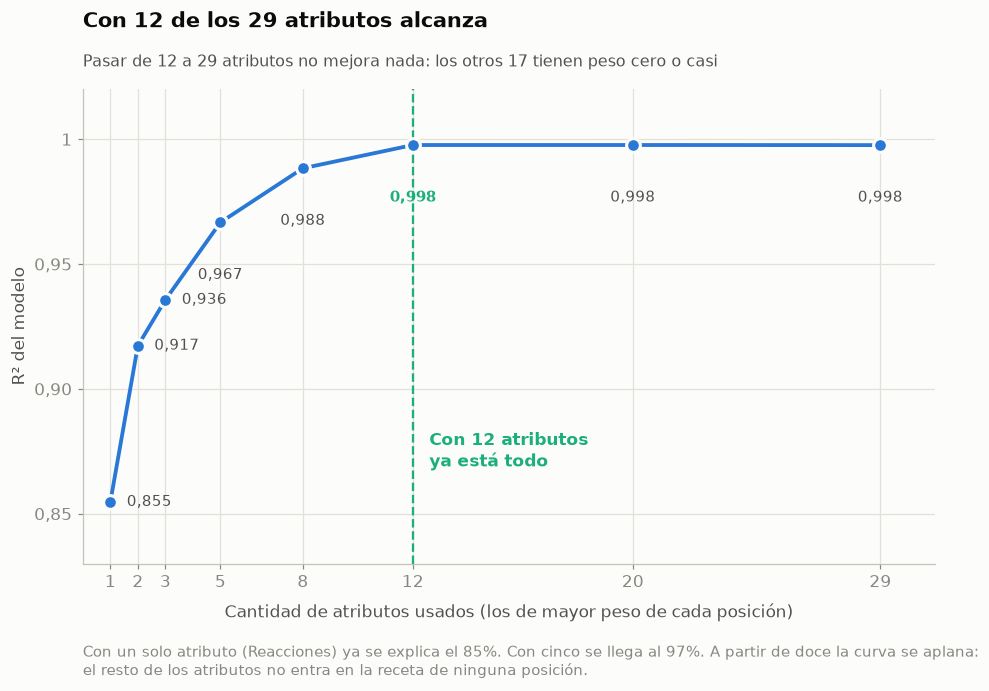

In [15]:
CANTIDADES = [1, 2, 3, 5, 8, 12, 20, 29]
curva = []

for k in CANTIDADES:
    r2_k, error_k = [], []
    for posicion in sorted(campo["position"].unique()):
        sub = campo[campo["position"] == posicion]
        # Los k atributos de mayor peso para esta posición
        base = LinearRegression().fit(sub[ATRIBUTOS], sub["ovr"])
        mejores = pd.Series(base.coef_, index=ATRIBUTOS).sort_values(ascending=False).head(k).index.tolist()

        X_entren, X_prueba, y_entren, y_prueba = train_test_split(
            sub[mejores], sub["ovr"], test_size=0.25, random_state=SEMILLA
        )
        predicho = LinearRegression().fit(X_entren, y_entren).predict(X_prueba)
        r2_k.append(r2_score(y_prueba, predicho))
        error_k.append(mean_absolute_error(y_prueba, predicho))
    curva.append({"atributos": k, "R²": np.mean(r2_k), "error": np.mean(error_k)})

tabla_curva = pd.DataFrame(curva)
print(tabla_curva.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.plot(tabla_curva["atributos"], tabla_curva["R²"], color=AZUL, linewidth=2.5,
        marker="o", markersize=9, markeredgecolor=SUPERFICIE, markeredgewidth=2, zorder=3)

for _, fila in tabla_curva.iterrows():
    k = int(fila["atributos"])
    destacar = k == 12
    # En el tramo empinado la etiqueta va al costado; si no, choca con la curva
    if k <= 3:
        ax.text(k + 0.6, fila["R²"], coma(fila["R²"], 3), ha="left", va="center",
                fontsize=10, color=TINTA_SUAVE)
    else:
        ax.text(k, fila["R²"] - 0.018, coma(fila["R²"], 3), ha="center", va="top",
                fontsize=10, fontweight="bold" if destacar else "normal",
                color=AQUA if destacar else TINTA_SUAVE)

ax.axvline(12, color=AQUA, linewidth=1.5, linestyle="--", zorder=2)
ax.text(12.6, 0.875, "Con 12 atributos\nya está todo", fontsize=11, fontweight="bold",
        color=AQUA, va="center", ha="left")

ax.set_xlim(0, 31)
ax.set_ylim(0.83, 1.02)
ax.set_xticks(CANTIDADES)
ax.set_yticks([0.85, 0.90, 0.95, 1.0], ["0,85", "0,90", "0,95", "1"])
ax.set_xlabel("Cantidad de atributos usados (los de mayor peso de cada posición)", labelpad=8)
ax.set_ylabel("R² del modelo")
ax.grid(True, zorder=0)
ax.set_axisbelow(True)

poner_titulo(ax, "Con 12 de los 29 atributos alcanza",
             "Pasar de 12 a 29 atributos no mejora nada: los otros 17 tienen peso cero o casi",
             alto=(1.12, 1.04))
ax.text(0, -0.17,
        "Con un solo atributo (Reacciones) ya se explica el 85%. Con cinco se llega al 97%. "
        "A partir de doce la curva se aplana:\nel resto de los atributos no entra en la receta de ninguna posición.",
        transform=ax.transAxes, fontsize=9.5, color=TINTA_TENUE, va="top", ha="left")

guardar(fig, "19_cuantos_atributos.png")
plt.show()

## Gráfico 20 — ¿Dónde se equivoca el modelo?

El error medio de 0,29 es un promedio, y los promedios esconden cosas. Lo abrimos por
nivel de jugador para ver si el modelo falla parejo o si hay zonas donde falla más.

       jugadores  error_medio  error_absoluto
banda                                        
47-55        192        0.000           0.273
56-60        443        0.027           0.283
61-65        970       -0.001           0.280
66-70       1138        0.002           0.282
71-75        768        0.007           0.285
76-80        344        0.043           0.292
81-91        113       -0.275           0.452
✓ 20_donde_falla_el_modelo.png


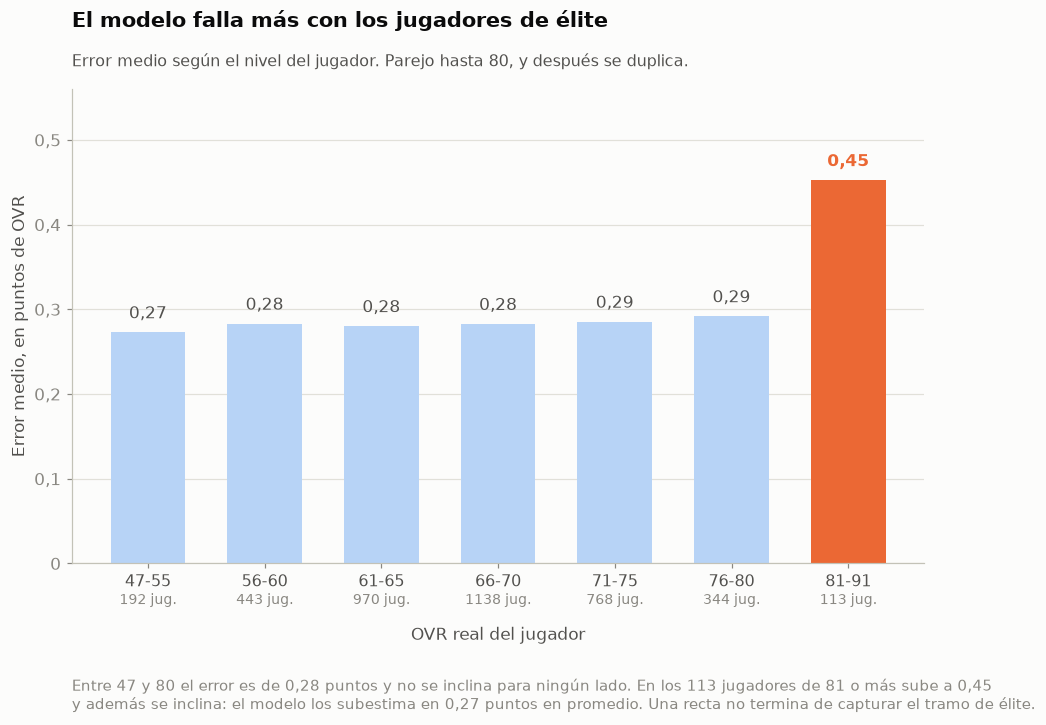

In [16]:
analisis_error = pd.DataFrame({"real": y_real, "predicho": y_pred, "error": errores})
analisis_error["banda"] = pd.cut(
    analisis_error["real"], [44, 55, 60, 65, 70, 75, 80, 95],
    labels=["47-55", "56-60", "61-65", "66-70", "71-75", "76-80", "81-91"],
)

por_banda = analisis_error.groupby("banda", observed=True).agg(
    jugadores=("error", "size"),
    error_medio=("error", "mean"),
    error_absoluto=("error", lambda e: e.abs().mean()),
)
print(por_banda.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 5.6))
colores_banda = [NARANJA if b == "81-91" else AZUL_CLARO for b in por_banda.index]
ax.bar(range(len(por_banda)), por_banda["error_absoluto"], color=colores_banda, width=0.64)

for i, (banda, fila) in enumerate(por_banda.iterrows()):
    destacar = banda == "81-91"
    ax.text(i, fila["error_absoluto"] + 0.012, coma(fila["error_absoluto"]),
            ha="center", va="bottom", fontsize=11,
            fontweight="bold" if destacar else "normal",
            color=NARANJA if destacar else TINTA_SUAVE)
    ax.text(i, -0.035, f"{int(fila['jugadores'])} jug.", ha="center", va="top",
            fontsize=9, color=TINTA_TENUE)

ax.set_xticks(range(len(por_banda)), list(por_banda.index), fontsize=10.5, color=TINTA_SUAVE)
ax.set_ylim(0, 0.56)
ax.set_yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5], ["0", "0,1", "0,2", "0,3", "0,4", "0,5"])
ax.set_xlabel("OVR real del jugador", labelpad=24)
ax.set_ylabel("Error medio, en puntos de OVR")
ax.yaxis.grid(True, zorder=0)
ax.set_axisbelow(True)

poner_titulo(ax, "El modelo falla más con los jugadores de élite",
             "Error medio según el nivel del jugador. Parejo hasta 80, y después se duplica.",
             alto=(1.12, 1.04))
ax.text(0, -0.24,
        "Entre 47 y 80 el error es de 0,28 puntos y no se inclina para ningún lado. En los 113 jugadores de 81 o más "
        "sube a 0,45\ny además se inclina: el modelo los subestima en 0,27 puntos en promedio. "
        "Una recta no termina de capturar el tramo de élite.",
        transform=ax.transAxes, fontsize=9.5, color=TINTA_TENUE, va="top", ha="left")

guardar(fig, "20_donde_falla_el_modelo.png")
plt.show()

**Una limitación honesta del trabajo.** El modelo es lineal: supone que subir 1 punto de
definición suma siempre lo mismo, valga el jugador 60 u 85. Los datos dicen que en el
tramo de élite eso no se cumple del todo, y por eso los subestima.

Es poco: 0,45 puntos sobre un OVR de 1 a 99. Pero es una pista de que arriba de 80 hay
algo que una recta no captura — quizás un ajuste que EA aplica a los jugadores top.